## MLP Classificator - Modelo Propuesta

Dentro de este notebook se utiliza la parte de BaseModeling y utiliza el mismo dataset, `TARGET` y la misma separacion de conjuntos.

Cabe mencionar que se esta utilizando a Geeks for geeks como referencia del codigo: https://www.geeksforgeeks.org/machine-learning/classification-using-sklearn-multi-layer-perceptron/

### 1-. Librerias y rutas

In [23]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import loguniform

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

In [24]:
IN_COLAB = 'google.colab' in sys.modules
SEED = 42

In [25]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
  RUTA_MODELOS = Path("/content/drive/My Drive/Modelos")
else:
  print("Running Local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  RUTA_MODELOS = Path.cwd() / ".." / ".." / "models"
  print(RUTA_DATOS)

RUTA_MODELOS.mkdir(parents=True, exist_ok=True)

Mount Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### 2. Cargar datset final

In [26]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

df_final = load_dataset("dataset_final_serie_tiempo.parquet")

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']


### 3. Parametros

In [27]:
PCT_COL = "pct_posible_cola"
TARGET = PCT_COL
UMBRAL_COL = 0.5
N_FOLDS = 5
TEST_SIZE = 0.15

N_ITER_ETAPA1 = 8 # Combinaciones aleatorias en la busqueda amplia (8 x 5 folds = 40 entrenamientos)

In [28]:
def a_cola(pct):
  return (np.asarray(pct) > UMBRAL_COL).astype(int) # Convierte la proporcion en clase binaria

In [29]:
df_final = df_final.dropna(subset=[PCT_COL]).reset_index(drop=True)
df_final["produccion_promedio"] = df_final["produccion_promedio"].fillna(0)
df_final["hay_cola"] = a_cola(df_final[PCT_COL])

In [30]:
COLS_ORDENIO = [
  "total_ordenios", "produccion_promedio", "duracion_total_min", "patadas_totales",
  "desviaciones_leche_totales", "ordenios_con_lavado", "pct_primer_parto", "pct_fresca",
  "pct_alta", "pct_baja", "pct_extendida", "hubo_ordenios", "pct_ocupacion_robot",
  "hubo_lavado", "ordenios_otros_robots", "sin_etapa", "vacas_activas_dia",
]

COLS_ORDENIO = [c for c in COLS_ORDENIO if c in df_final.columns]

df_final = df_final.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)
g = df_final.groupby("ms")
contiguo = (df_final["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")

for c in COLS_ORDENIO:
  df_final[f"{c}_anterior"] = g[c].shift(1).where(contiguo)
df_final["pct_cola_anterior"] = g[PCT_COL].shift(1).where(contiguo)

df_final = df_final.drop(columns=COLS_ORDENIO)
df_final = df_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

print(f"Variables desfasadas: {len(COLS_ORDENIO)} (+ pct_cola_anterior)")
print(f"Bloques sin bloque anterior contiguo: {(~contiguo).sum():,} ({(~contiguo).mean():.1%}) -> se imputan")
print("Columnas finales:", [c for c in df_final.columns if c not in (PCT_COL, 'hay_cola', 'bloque_tiempo')])

Variables desfasadas: 17 (+ pct_cola_anterior)
Bloques sin bloque anterior contiguo: 3 (0.0%) -> se imputan
Columnas finales: ['ms', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'total_ordenios_anterior', 'produccion_promedio_anterior', 'duracion_total_min_anterior', 'patadas_totales_anterior', 'desviaciones_leche_totales_anterior', 'ordenios_con_lavado_anterior', 'pct_primer_parto_anterior', 'pct_fresca_anterior', 'pct_alta_anterior', 'pct_baja_anterior', 'pct_extendida_anterior', 'hubo_ordenios_anterior', 'pct_ocupacion_robot_anterior', 'hubo_lavado_anterior', 'ordenios_otros_robots_anterior', 'sin_etapa_anterior', 'vacas_activas_dia_anterior', 'pct_cola_anterior']


In [31]:
df_final = df_final.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)
g = df_final.groupby("ms")

def lag(col, k):
  ok = (df_final["bloque_tiempo"] - g["bloque_tiempo"].shift(k)) == pd.Timedelta(minutes=30 * k)
  return g[col].shift(k).where(ok)

def media_movil(col_anterior, n):
  return df_final.groupby("ms")[col_anterior].transform(lambda s: s.rolling(n, min_periods=1).mean())

for k in (2, 3, 4):
  df_final[f"pct_cola_t-{k}"] = lag(PCT_COL, k)
df_final["pct_cola_ayer_misma_hora"] = lag(PCT_COL, 48)
df_final["pct_cola_semana_pasada"] = lag(PCT_COL, 336)

df_final["pct_cola_media_2h"] = media_movil("pct_cola_anterior", 4)
df_final["pct_cola_media_6h"] = media_movil("pct_cola_anterior", 12)
df_final["pct_cola_media_24h"] = media_movil("pct_cola_anterior", 48)
df_final["ocupacion_media_2h"] = media_movil("pct_ocupacion_robot_anterior", 4)
df_final["ordenios_media_2h"] = media_movil("total_ordenios_anterior", 4)

# Cola de toda la granja (3 robots) en el bloque anterior
granja = df_final.groupby("bloque_tiempo")[PCT_COL].mean().sort_index()
granja_prev = granja.shift(1).where(granja.index.to_series().diff() == pd.Timedelta("30min"))
df_final["pct_cola_granja_anterior"] = df_final["bloque_tiempo"].map(granja_prev)

# Hora cíclica
df_final["hora_sin"] = np.sin(2 * np.pi * df_final["hora"] / 24)
df_final["hora_cos"] = np.cos(2 * np.pi * df_final["hora"] / 24)

df_final = df_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)
nuevas = [c for c in df_final.columns if c.startswith(("pct_cola_", "ocupacion_media", "ordenios_media", "hora_"))]
print(f"Variables de historial agregadas: {len(nuevas)}")
print(nuevas)

Variables de historial agregadas: 14
['pct_cola_anterior', 'pct_cola_t-2', 'pct_cola_t-3', 'pct_cola_t-4', 'pct_cola_ayer_misma_hora', 'pct_cola_semana_pasada', 'pct_cola_media_2h', 'pct_cola_media_6h', 'pct_cola_media_24h', 'ocupacion_media_2h', 'ordenios_media_2h', 'pct_cola_granja_anterior', 'hora_sin', 'hora_cos']


### 4-. Separacion train/test y folds

In [32]:
df_model = pd.get_dummies(df_final, columns=["ms", "temporada"], dtype="float32")

corte = int(len(df_model) * (1-TEST_SIZE))
df_tr, df_te = df_model.iloc[:corte], df_model.iloc[corte:]

columnas_excluir = [PCT_COL, "hay_cola", "bloque_tiempo"]
X_train, y_train = df_tr.drop(columns=columnas_excluir), df_tr["hay_cola"]
X_test, y_test = df_te.drop(columns=columnas_excluir), df_te["hay_cola"]

no_num = X_train.select_dtypes(exclude="number").columns.tolist()
assert not no_num, f"Columnas no numericas pendientes de codificar: {no_num}"

print(f"Train: {len(X_train):,} bloques ({df_tr['bloque_tiempo'].min():%Y-%m-%d} a {df_tr['bloque_tiempo'].max():%Y-%m-%d})")
print(f"Test: {len(X_test):,} bloques ({df_te['bloque_tiempo'].min():%Y-%m-%d} a {df_te['bloque_tiempo'].max():%Y-%m-%d}")
print(f"Variables de entrada: {X_train.shape[1]}")

Train: 152,872 bloques (2022-08-01 a 2025-06-27)
Test: 26,978 bloques (2025-06-27 a 2025-12-31
Variables de entrada: 41


,fold,entrenamiento,validacion,bloques_ent,bloques_val
0,1,2022-08-01 a 2023-01-24,2023-01-25 a 2023-07-20,25482,25478
1,2,2022-08-01 a 2023-07-20,2023-07-20 a 2024-01-13,50960,25478
2,3,2022-08-01 a 2024-01-13,2024-01-13 a 2024-07-08,76438,25478
3,4,2022-08-01 a 2024-07-08,2024-07-08 a 2025-01-01,101916,25478
4,5,2022-08-01 a 2025-01-01,2025-01-01 a 2025-06-27,127394,25478


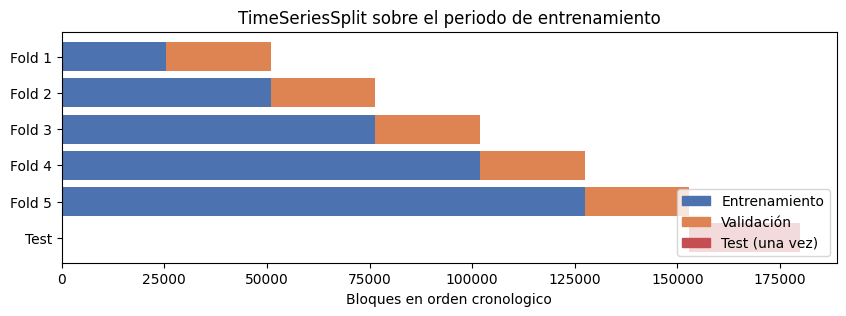

In [33]:
from IPython.core.pylabtools import figsize
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

folds= []
t = df_tr["bloque_tiempo"]
for i, (idx_ent, idx_val) in enumerate(tscv.split(X_train), start=1):
  folds.append({
      "fold": i,
      "entrenamiento": f"{t.iloc[idx_ent[0]]:%Y-%m-%d} a {t.iloc[idx_ent[-1]]:%Y-%m-%d}",
      "validacion": f"{t.iloc[idx_val[0]]:%Y-%m-%d} a {t.iloc[idx_val[-1]]:%Y-%m-%d}",
      "bloques_ent": len(idx_ent),
      "bloques_val": len(idx_val),
  })
display(pd.DataFrame(folds))

fig, ax = plt.subplots(figsize=(10,3))
n = len(X_train)
for i, (idx_ent, idx_val) in enumerate(tscv.split(X_train)):
  ax.barh(i, len(idx_ent), left = 0, color= "#4C72B0")
  ax.barh(i, len(idx_val), left = idx_val[0], color= "#DD8452")
ax.barh(N_FOLDS, len(X_test), left=n, color= "#C44E52")
ax.set_yticks(range(N_FOLDS + 1), [f"Fold {i+1}" for i in range(N_FOLDS)] + ["Test"])
ax.invert_yaxis(); ax.set_xlabel("Bloques en orden cronologico")
ax.legend(handles=[plt.Rectangle((0,0),1,1,color=c) for c in ["#4C72B0","#DD8452","#C44E52"]],
          labels=["Entrenamiento", "Validación", "Test (una vez)"], loc="lower right")
ax.set_title("TimeSeriesSplit sobre el periodo de entrenamiento")
plt.show()

In [34]:
balance = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}).rename(index={0: "Sin cola(0)", 1:"cola(1)"}).round(3)
display(balance)


p_test= y_test.mean()
print(f"Proporcion de cola en test: {p_test:.3f}, F1 baseline de que siempre haya cola = {2*p_test/(1+p_test):.3f}")

,train,test
hay_cola,,
Sin cola(0),0.804,0.425
cola(1),0.196,0.575


Proporcion de cola en test: 0.575, F1 baseline de que siempre haya cola = 0.730


### 5-. Baselines sin modelo
- predice que siempre hay cola para todos los bloques, es mas que nada una comparacion para el modelo

In [35]:
cola_anterior = df_final.groupby("ms")["hay_cola"].shift(1)
cola_anterior_test = cola_anterior.iloc[corte:]
mask_prev = cola_anterior_test.notna().values

y_test_cls = y_test.values

def metricas_cls(y_real, y_pred):
  return {
    "F1": f1_score(y_real, y_pred, zero_division=0),
    "Precisión": precision_score(y_real, y_pred, zero_division=0),
    "Recall": recall_score(y_real, y_pred, zero_division=0),
  }

resultados = {
  "Siempre cola": metricas_cls(y_test_cls, np.ones_like(y_test_cls)),
  "Bloque anterior": metricas_cls(y_test_cls[mask_prev], cola_anterior_test[mask_prev].astype(int)),
}
display(pd.DataFrame(resultados).T.round(3))

,F1,Precisión,Recall
Siempre cola,0.730,0.575,1.000
Bloque anterior,0.667,0.667,0.667


### 6-. Pipeline del modelo

In [36]:
pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        solver="adam",
        max_iter=100,
        early_stopping=False,
        random_state=SEED,
  )),
])

### 7-. Busqueda de hiperparametros

En este caso se utiliza `GridSearchCV` para eligir los mejores valores de la lista de valores. Primero se utiliza `RandomizedSearchCV` para probar combinaciones al azar dentro del rango en donde el modelo funciona mejor y posteriormente `GridSearchCV` se utiliza para elegir a los hiperparametros ganadores.

In [37]:
param_dist = {
  "mlp__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64)],
  "mlp__alpha": loguniform(1e-5, 1e-1),
  "mlp__learning_rate_init": loguniform(1e-4, 1e-2),
  "mlp__batch_size": [256, 512],
  "mlp__activation": ["relu", "tanh"],
}

e1 = RandomizedSearchCV(
    pipe, param_dist, n_iter = N_ITER_ETAPA1,
    cv=tscv, scoring="f1",refit=False, random_state=SEED,
    n_jobs=1, verbose=2,
)

inicio = time.time()
e1.fit(X_train, y_train)
print(f"Tiempo etapa 1: {(time.time() - inicio)/60:.1f} min")
print("Mejores parametros:", e1.best_params_)
print(f"F1 promedio en CV: {e1.best_score_:.3f}")

Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END mlp__activation=relu, mlp__alpha=0.015352246941973482, mlp__batch_size=256, mlp__hidden_layer_sizes=(128,), mlp__learning_rate_init=0.0036256176345762273; total time=  17.2s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END mlp__activation=relu, mlp__alpha=0.015352246941973482, mlp__batch_size=256, mlp__hidden_layer_sizes=(128,), mlp__learning_rate_init=0.0036256176345762273; total time=  32.6s
[CV] END mlp__activation=relu, mlp__alpha=0.015352246941973482, mlp__batch_size=256, mlp__hidden_layer_sizes=(128,), mlp__learning_rate_init=0.0036256176345762273; total time=  26.9s
[CV] END mlp__activation=relu, mlp__alpha=0.015352246941973482, mlp__batch_size=256, mlp__hidden_layer_sizes=(128,), mlp__learning_rate_init=0.0036256176345762273; total time=  22.0s
[CV] END mlp__activation=relu, mlp__alpha=0.015352246941973482, mlp__batch_size=256, mlp__hidden_layer_sizes=(128,), mlp__learning_rate_init=0.0036256176345762273; total time=  31.0s


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


... (48 outputs left out)

[CV] END mlp__activation=tanh, mlp__alpha=0.00234238498471129, mlp__batch_size=256, mlp__hidden_layer_sizes=(128, 64), mlp__learning_rate_init=0.0016409286730647919; total time= 1.5min


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV] END mlp__activation=tanh, mlp__alpha=0.00234238498471129, mlp__batch_size=256, mlp__hidden_layer_sizes=(128, 64), mlp__learning_rate_init=0.0016409286730647919; total time= 2.0min
[CV] END mlp__activation=tanh, mlp__alpha=0.00234238498471129, mlp__batch_size=256, mlp__hidden_layer_sizes=(128, 64), mlp__learning_rate_init=0.0016409286730647919; total time= 2.8min
Tiempo etapa 1: 27.3 min
Mejores parametros: {'mlp__activation': 'tanh', 'mlp__alpha': np.float64(0.00234238498471129), 'mlp__batch_size': 256, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': np.float64(0.0016409286730647919)}
F1 promedio en CV: 0.235


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,alpha,learning_rate_init,batch_size,activation,F1 (media),F1 (desv.),rank
7,"(128, 64)",0.00234,0.00164,256,tanh,0.23536,0.10178,1
4,"(128, 64)",0.00295,0.00073,512,relu,0.19188,0.15562,2
1,"(128,)",0.00004,0.00083,256,relu,0.16390,0.14365,3
3,"(64,)",0.00773,0.00023,512,tanh,0.14427,0.17385,4
6,"(128,)",0.00029,0.00058,512,tanh,0.13684,0.13472,5
2,"(128,)",0.00254,0.00011,512,relu,0.12270,0.17170,6
5,"(64,)",0.00126,0.00012,256,relu,0.10787,0.16148,7
0,"(128,)",0.01535,0.00363,256,relu,0.07541,0.08140,8


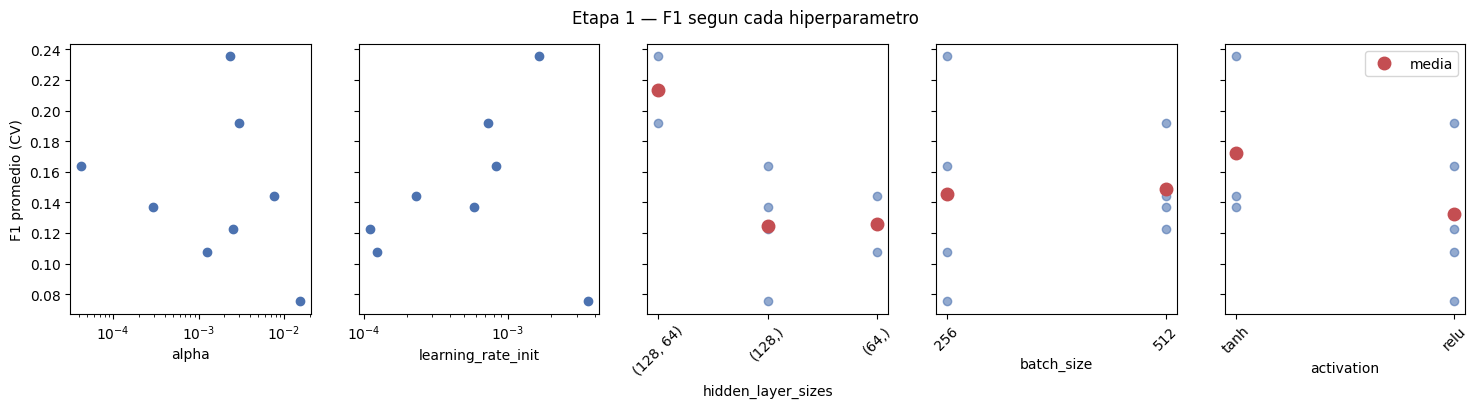

In [38]:
r1 = pd.DataFrame(e1.cv_results_)
tabla_e1 = (r1[["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "param_mlp__learning_rate_init",
                "param_mlp__batch_size", "param_mlp__activation", "mean_test_score", "std_test_score", "rank_test_score"]]
            .rename(columns=lambda c: c.replace("param_mlp__", ""))
            .rename(columns={"mean_test_score": "F1 (media)", "std_test_score": "F1 (desv.)", "rank_test_score": "rank"})
            .sort_values("rank"))
display(tabla_e1.round(5))

fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
y_f1 = tabla_e1["F1 (media)"]
for ax, col, log in zip(axes, ["alpha", "learning_rate_init"], [True, True]):
  ax.scatter(tabla_e1[col].astype(float), y_f1, color="#4C72B0")
  ax.set_xscale("log"); ax.set_xlabel(col)
for ax, col in zip(axes[2:], ["hidden_layer_sizes", "batch_size", "activation"]):
  g = tabla_e1.assign(**{col: tabla_e1[col].astype(str)}).groupby(col)["F1 (media)"]
  ax.scatter(tabla_e1[col].astype(str), y_f1, color="#4C72B0", alpha=.6)
  ax.plot(g.mean().index, g.mean().values, "o", color="#C44E52", ms=9, label="media")
  ax.set_xlabel(col); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("F1 promedio (CV)")
axes[-1].legend()
fig.suptitle("Etapa 1 — F1 segun cada hiperparametro")
plt.show()

In [39]:
b = e1.best_params_
param_grid_fino = {
  "mlp__hidden_layer_sizes": [b["mlp__hidden_layer_sizes"]],
  "mlp__batch_size": [b["mlp__batch_size"]],
  "mlp__activation": [b["mlp__activation"]],
  "mlp__alpha": [b["mlp__alpha"]],
  "mlp__learning_rate_init": [b["mlp__learning_rate_init"] * f for f in (0.5, 1, 2)],
}

grid = GridSearchCV(
  pipe, param_grid_fino,
  cv=tscv, scoring="f1", refit=True,
  n_jobs=-1, verbose=2,
)

inicio = time.time()
grid.fit(X_train, y_train)
print(f"Tiempo etapa 2: {(time.time() - inicio)/60:.1f} min")
print("Mejores parámetros (finales):", grid.best_params_)
print(f"F1 promedio en CV: {grid.best_score_:.3f}  (etapa 1: {e1.best_score_:.3f})")

Fitting 5 folds for each of 3 candidates, totalling 15 fits
Tiempo etapa 2: 15.9 min
Mejores parámetros (finales): {'mlp__activation': 'tanh', 'mlp__alpha': np.float64(0.00234238498471129), 'mlp__batch_size': 256, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': np.float64(0.0016409286730647919)}
F1 promedio en CV: 0.235  (etapa 1: 0.235)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


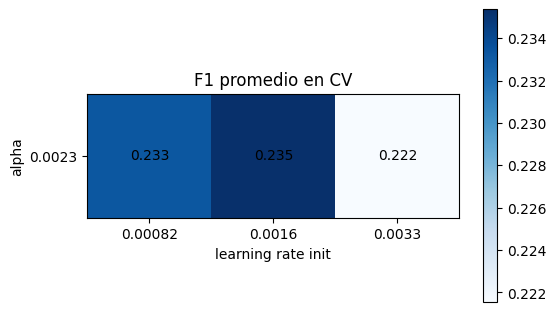

In [40]:
r2 = pd.DataFrame(grid.cv_results_)
piv = r2.pivot_table(index="param_mlp__alpha", columns="param_mlp__learning_rate_init", values="mean_test_score")
fig,ax = plt.subplots(figsize=(6,3.8))
im = ax.imshow(piv.values, cmap="Blues")
ax.set_xticks(range(len(piv.columns)), [f"{v:.2g}" for v in piv.columns])
ax.set_yticks(range(len(piv.index)), [f"{v:.2g}" for v in piv.index])
for i in range(piv.shape[0]):
  for j in range(piv.shape[1]):
    ax.text(j, i, f"{piv.values[i,j]:.3f}", ha="center", va="center")
ax.set_xlabel("learning rate init"), ax.set_ylabel("alpha")
ax.set_title("F1 promedio en CV")
plt.colorbar(im); plt.show()


### 8. Curva de perida del mejor modelo

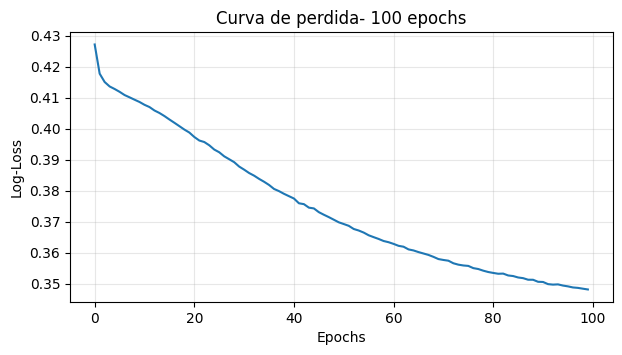

Arquitectura: 41 entradas → (128, 64) (tanh) → 1 salida (logistic)


In [41]:
mejor = grid.best_estimator_
mlp = mejor.named_steps["mlp"]

plt.figure(figsize=(7, 3.5))
plt.plot(mlp.loss_curve_)
plt.xlabel("Epochs"); plt.ylabel("Log-Loss")
plt.title(f"Curva de perdida- {mlp.n_iter_} epochs")
plt.grid(alpha=.3); plt.show()
print(f"Arquitectura: {X_train.shape[1]} entradas → {mlp.hidden_layer_sizes} ({mlp.activation}) → 1 salida ({mlp.out_activation_})")

### Umbral de desicion

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


Umbral elegido: 0.05  (F1 en validación = 0.599; con 0.5 = 0.400)


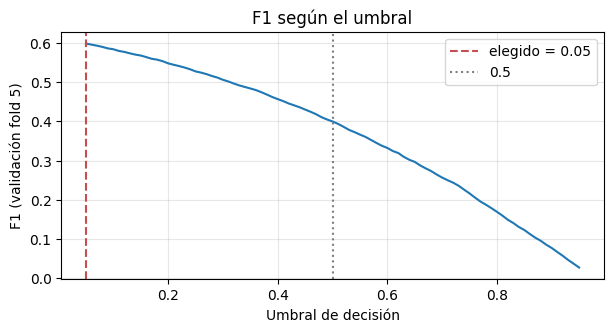

In [42]:
from sklearn.base import clone

idx_ent, idx_val = list(tscv.split(X_train))[-1]
m_val = clone(mejor).fit(X_train.iloc[idx_ent], y_train.iloc[idx_ent])
p_val = m_val.predict_proba(X_train.iloc[idx_val])[:, 1]
y_val = y_train.iloc[idx_val].values

umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
f1s = np.array([f1_score(y_val, (p_val >= u).astype(int), zero_division=0) for u in umbrales])
UMBRAL_DEC = float(umbrales[f1s.argmax()])
print(f"Umbral elegido: {UMBRAL_DEC:.2f}  (F1 en validación = {f1s.max():.3f}; con 0.5 = {f1s[umbrales == 0.5][0]:.3f})")

plt.figure(figsize=(7, 3.2))
plt.plot(umbrales, f1s); plt.axvline(UMBRAL_DEC, color="#C44E52", ls="--", label=f"elegido = {UMBRAL_DEC:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="0.5")
plt.xlabel("Umbral de decisión"); plt.ylabel("F1 (validación fold 5)")
plt.title("F1 según el umbral"); plt.legend(); plt.grid(alpha=.3); plt.show()

### 10. Evaluacion en test

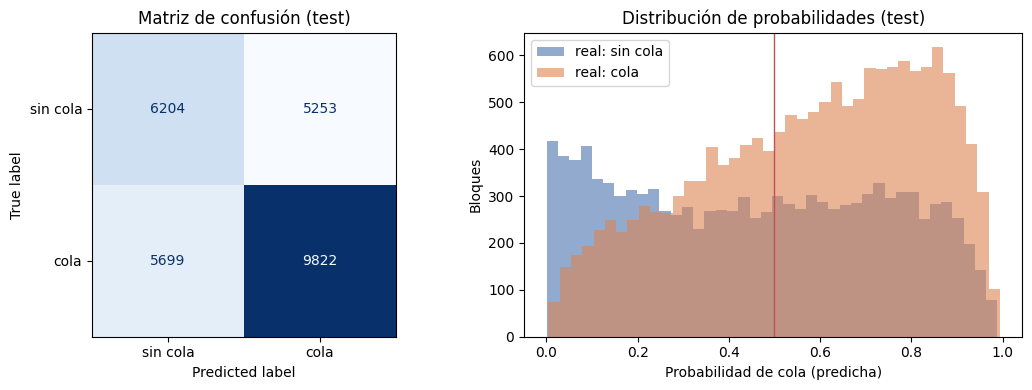

In [43]:
prob_cola = mejor.predict_proba(X_test)[:, 1]
pred_cls = (prob_cola >= 0.5).astype(int)

resultados["MLP Classifier"] = metricas_cls(y_test_cls, pred_cls)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test_cls, pred_cls),
                       display_labels=["sin cola", "cola"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Matriz de confusión (test)")

axes[1].hist(prob_cola[y_test_cls == 0], bins=40, alpha=.6, label="real: sin cola", color="#4C72B0")
axes[1].hist(prob_cola[y_test_cls == 1], bins=40, alpha=.6, label="real: cola", color="#DD8452")
axes[1].axvline(0.5, color="#C44E52", lw=1)
axes[1].set_xlabel("Probabilidad de cola (predicha)"); axes[1].set_ylabel("Bloques")
axes[1].set_title("Distribución de probabilidades (test)"); axes[1].legend()
plt.tight_layout(); plt.show()

### 11. Comparacion contra baselines y criterio de exito

,F1,Precisión,Recall
Siempre cola,0.730,0.575,1.000
Bloque anterior,0.667,0.667,0.667
MLP Classifier,0.642,0.652,0.633


F1 > 0.60: si   |   Mejor que ambos baselines: No


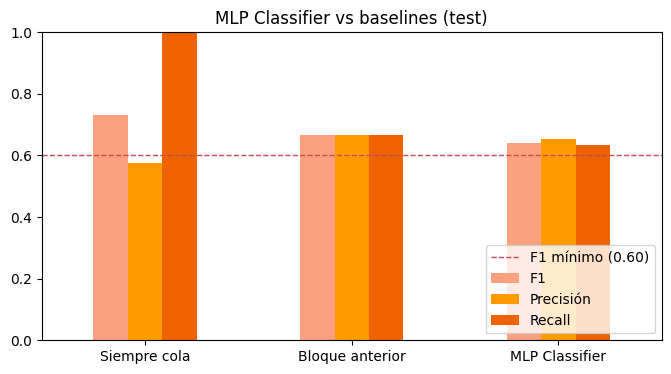

In [44]:
comp = pd.DataFrame(resultados).T.round(3)
display(comp)

f1_mlp = comp.loc["MLP Classifier", "F1"]
supera = f1_mlp > comp.loc[["Siempre cola", "Bloque anterior"], "F1"].max()
print(f"F1 > 0.60: {'si' if f1_mlp > 0.60 else 'No'}   |   Mejor que ambos baselines: {'Si' if supera else 'No'}")

ax = comp.plot.bar(figsize=(8, 4), rot=0, color=["#FBA17E", "#FF9A00", "#EE6200"])
ax.axhline(0.60, ls="--", color="#C44E52", lw=1, label="F1 mínimo (0.60)")
ax.set_ylim(0, 1); ax.set_title("MLP Classifier vs baselines (test)")
ax.legend(loc="lower right"); plt.show()

### 12. Importancia de variables

,variable,media,desv
20,pct_cola_anterior,0.0177,0.0012
28,pct_cola_media_24h,0.0167,0.0016
4,produccion_promedio_anterior,0.0098,0.0012
26,pct_cola_media_2h,0.0096,0.0020
19,vacas_activas_dia_anterior,0.0075,0.0011
2,min_desde_alimento,0.0068,0.0013
24,pct_cola_ayer_misma_hora,0.0062,0.0007
38,temporada_otoño,0.0049,0.0012
16,hubo_lavado_anterior,0.0043,0.0008
36,ms_VMS 3,0.0036,0.0011


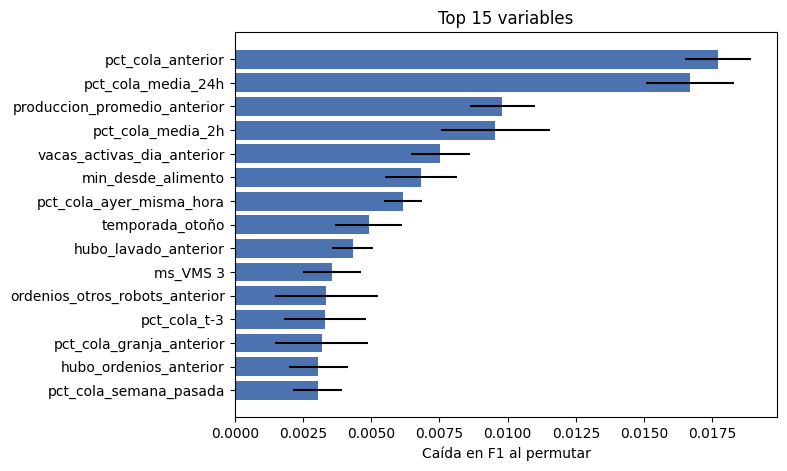

In [45]:
N_MAX = 20_000
X_pi, y_pi = X_test.iloc[-N_MAX:], y_test.iloc[-N_MAX:]

pi = permutation_importance(
  mejor, X_pi, y_pi, scoring="f1",
  n_repeats=5, random_state=SEED, n_jobs=-1,
)
imp = (pd.DataFrame({"variable": X_test.columns, "media": pi.importances_mean, "desv": pi.importances_std})
         .sort_values("media", ascending=False))
display(imp.head(15).round(4))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top["variable"], top["media"], xerr=top["desv"], color="#4C72B0")
plt.xlabel("Caída en F1 al permutar"); plt.title("Top 15 variables")
plt.show()